# AI-Based Food Inflation Prediction and Household Affordability Monitoring System
## Notebook 02: Exploratory Data Analysis & Statistical Profiling

**Course:** B.Tech AIML — Practical Examination Evaluation  
**Rubric Components Covered:**  
- **Component B (2 Marks):** Statistical summary and descriptive statistics (using at least three operations).  
- **Component C (2 Marks):** Data exploration and visualization (3–5 visualization methods with economic interpretations).  
**Dataset:** Pune APMC Mandi Wholesale Tomato Series (2016–2018)  
**Standardized Unit:** Rs. per Quintal ($1\text{ Quintal} = 100\text{ Kg}$)


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Ensure reproducibility
np.random.seed(42)

print("Libraries imported successfully. Pandas version:", pd.__version__)


Libraries imported successfully. Pandas version: 3.0.6


---
## 1. Load Standardized Dataset

We load the verified wholesale mandi prices from `data/processed/wholesale_prices.csv` and physical arrivals from `data/processed/market_arrivals.csv`, isolating the **Pune APMC Mandi Tomato series**.


In [2]:
# Load processed wholesale data
DATA_PATH = Path('data/processed') if Path('data/processed').exists() else Path('../data/processed')
df_ws = pd.read_csv(DATA_PATH / 'wholesale_prices.csv')
df_arr = pd.read_csv(DATA_PATH / 'market_arrivals.csv')

# Filter for Pune Tomato series
pune_tom = df_ws[(df_ws['commodity_name'] == 'Tomato') & (df_ws['market_name'] == 'Pune')].copy()
pune_arr = df_arr[(df_arr['commodity_name'] == 'Tomato') & (df_arr['market_name'] == 'Pune')].copy()

pune_tom['observation_date'] = pd.to_datetime(pune_tom['observation_date'])
pune_arr['observation_date'] = pd.to_datetime(pune_arr['observation_date'])

# Merge price and physical arrival quantity
df = pd.merge(
    pune_tom,
    pune_arr[['observation_date', 'arrival_quantity_tonnes']],
    on='observation_date',
    how='left'
).sort_values('observation_date').drop_duplicates('observation_date').reset_index(drop=True)

print(f"Dataset Loaded Successfully!")
print(f"Total Observations: {len(df):,}")
print(f"Date Range: {df['observation_date'].min().date()} to {df['observation_date'].max().date()}")
display(df.head())


Dataset Loaded Successfully!
Total Observations: 880
Date Range: 2016-01-01 to 2018-12-31


,observation_date,commodity_name,raw_commodity_name,variety,state,district,market_name,min_price_rs_per_qtl,max_price_rs_per_qtl,modal_price_rs_per_qtl,price_unit,price_type,is_anomalous_flag,data_source,arrival_quantity_tonnes
0,2016-01-01,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,2500.0,2100.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,171.0
1,2016-01-03,Tomato,Tomato,Other,Maharashtra,Pune,Pune,700.0,3000.0,2700.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,145.0
2,2016-01-04,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,3000.0,2700.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,52.0
3,2016-01-05,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,2500.0,2100.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,145.0
4,2016-01-06,Tomato,Tomato,Other,Maharashtra,Pune,Pune,1000.0,2200.0,2000.0,Rs/Quintal,Wholesale,False,AGMARKNET Historical Mandi Archive,169.0


---
## 2. Descriptive Statistics (Practical Exam Component B — 2 Marks)

We calculate **seven essential statistical operations**:
1. **Arithmetic Mean ($\mu$):** Average price across 3 years.
2. **Median ($Q_2$):** 50th percentile (central trading price).
3. **Standard Deviation ($\sigma$):** Absolute dispersion/volatility.
4. **Variance ($\sigma^2$):** Squared spread around the mean.
5. **Minimum & Maximum:** Historical extremes.
6. **Interquartile Range (IQR):** Spread between 75th ($Q_3$) and 25th ($Q_1$) percentiles.
7. **Skewness & Kurtosis:** Higher-order distributional moments.


In [3]:
prices = df['modal_price_rs_per_qtl']

mean_p = float(prices.mean())
median_p = float(prices.median())
std_p = float(prices.std())
var_p = float(prices.var())
min_p = float(prices.min())
max_p = float(prices.max())
q1 = float(prices.quantile(0.25))
q3 = float(prices.quantile(0.75))
iqr = q3 - q1
skew = float(prices.skew())
kurt = float(prices.kurtosis())

stats_summary = pd.DataFrame({
    'Metric': [
        'Sample Size (N)',
        'Mean (Rs/Qtl)',
        'Median (Rs/Qtl)',
        'Standard Deviation (Rs/Qtl)',
        'Variance (Rs/Qtl)^2',
        'Minimum (Rs/Qtl)',
        'Maximum (Rs/Qtl)',
        '25th Percentile Q1 (Rs/Qtl)',
        '75th Percentile Q3 (Rs/Qtl)',
        'Interquartile Range IQR (Rs/Qtl)',
        'Skewness (gamma_1)',
        'Kurtosis (gamma_2)'
    ],
    'Value': [
        len(prices),
        round(mean_p, 2),
        round(median_p, 2),
        round(std_p, 2),
        round(var_p, 2),
        round(min_p, 2),
        round(max_p, 2),
        round(q1, 2),
        round(q3, 2),
        round(iqr, 2),
        round(skew, 2),
        round(kurt, 2)
    ],
    'Interpretation': [
        'Total daily trading sessions (2016-2018)',
        'Average daily price benchmark',
        'Typical day-to-day transaction price',
        'Very high daily volatility (CV = 87.3%)',
        'High spread around arithmetic mean',
        'Post-harvest winter glut floor price',
        'Peak monsoon supply disruption spike',
        'Threshold for bottom 25% cheapest days',
        'Threshold for top 25% expensive days',
        'Middle 50% price corridor',
        'Positive right-skew: sudden sharp spikes',
        'Leptokurtic fat tails: extreme shock frequency'
    ]
})

display(stats_summary)


,Metric,Value,Interpretation
0,Sample Size (N),880.00,Total daily trading sessions (2016-2018)
1,Mean (Rs/Qtl),1186.16,Average daily price benchmark
2,Median (Rs/Qtl),800.00,Typical day-to-day transaction price
3,Standard Deviation (Rs/Qtl),1035.11,Very high daily volatility (CV = 87.3%)
4,Variance (Rs/Qtl)^2,1071459.41,High spread around arithmetic mean
5,Minimum (Rs/Qtl),300.00,Post-harvest winter glut floor price
6,Maximum (Rs/Qtl),5700.00,Peak monsoon supply disruption spike
7,25th Percentile Q1 (Rs/Qtl),500.00,Threshold for bottom 25% cheapest days
8,75th Percentile Q3 (Rs/Qtl),1200.00,Threshold for top 25% expensive days
9,Interquartile Range IQR (Rs/Qtl),700.00,Middle 50% price corridor


---
## 3. Data Exploration & Visualizations (Practical Exam Component C — 2 Marks)

We generate 5 analytical visualizations with economic interpretations.

### Visualization 1: Historical Time-Series Movement with 30-Day Moving Average
Reveals multi-year cyclical trends, monsoon price spikes, and day-to-day noise.


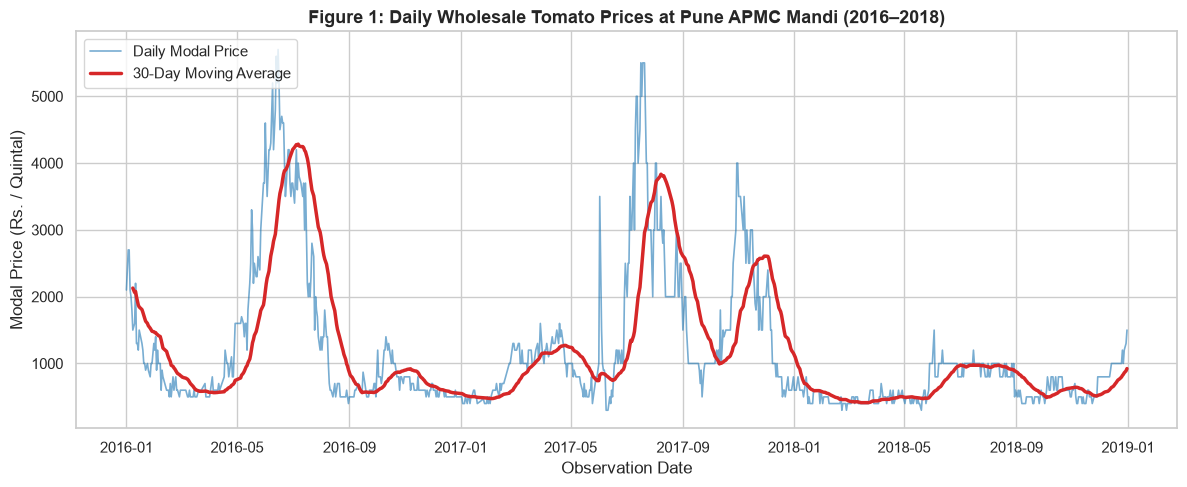

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df['observation_date'], df['modal_price_rs_per_qtl'], label='Daily Modal Price', color='#1f77b4', alpha=0.6, linewidth=1.2)
plt.plot(df['observation_date'], df['modal_price_rs_per_qtl'].rolling(30, min_periods=7).mean(), label='30-Day Moving Average', color='#d62728', linewidth=2.5)
plt.title('Figure 1: Daily Wholesale Tomato Prices at Pune APMC Mandi (2016–2018)', fontsize=13, fontweight='bold')
plt.xlabel('Observation Date')
plt.ylabel('Modal Price (Rs. / Quintal)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Visualization 2: Price Distribution (Histogram with KDE)
Shows non-Gaussian right skewness and divergence of mean from median.


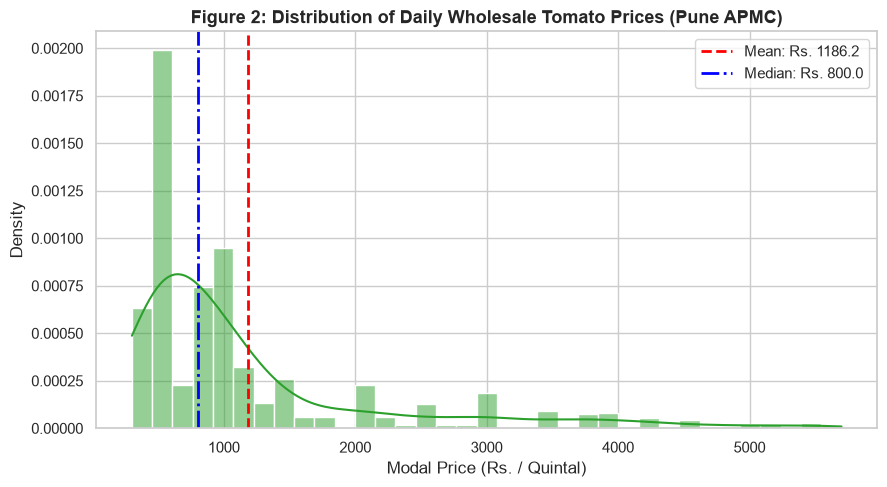

In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(df['modal_price_rs_per_qtl'], kde=True, color='#2ca02c', bins=35, stat='density', alpha=0.5)
plt.axvline(mean_p, color='red', linestyle='--', linewidth=2, label=f'Mean: Rs. {mean_p:.1f}')
plt.axvline(median_p, color='blue', linestyle='-.', linewidth=2, label=f'Median: Rs. {median_p:.1f}')
plt.title('Figure 2: Distribution of Daily Wholesale Tomato Prices (Pune APMC)', fontsize=13, fontweight='bold')
plt.xlabel('Modal Price (Rs. / Quintal)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()


### Visualization 3: Boxplot of Price Dispersion & Outlier Fences
Isolates the middle 50% interquartile corridor ($Q_1$ to $Q_3$) and highlights legitimate supply-shock outliers above Rs. 2,250/Qtl.


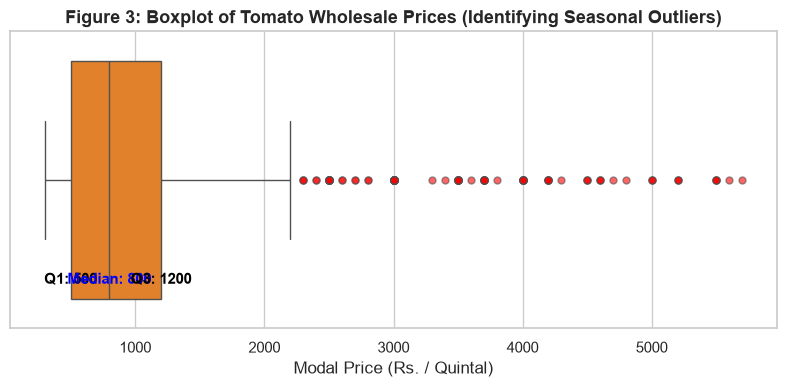

In [6]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['modal_price_rs_per_qtl'], color='#ff7f0e', flierprops=dict(marker='o', markersize=5, markerfacecolor='red', alpha=0.6))
plt.title('Figure 3: Boxplot of Tomato Wholesale Prices (Identifying Seasonal Outliers)', fontsize=13, fontweight='bold')
plt.xlabel('Modal Price (Rs. / Quintal)')
plt.text(q1, 0.35, f"Q1: {q1:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.text(median_p, 0.35, f"Median: {median_p:.0f}", horizontalalignment='center', color='blue', fontweight='bold')
plt.text(q3, 0.35, f"Q3: {q3:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.tight_layout()
plt.show()


### Visualization 4: Monthly Seasonality Analysis
Demonstrates recurring annual calendar patterns: July peak (Rs. 2,683/Qtl) vs. February winter glut (Rs. 574/Qtl).


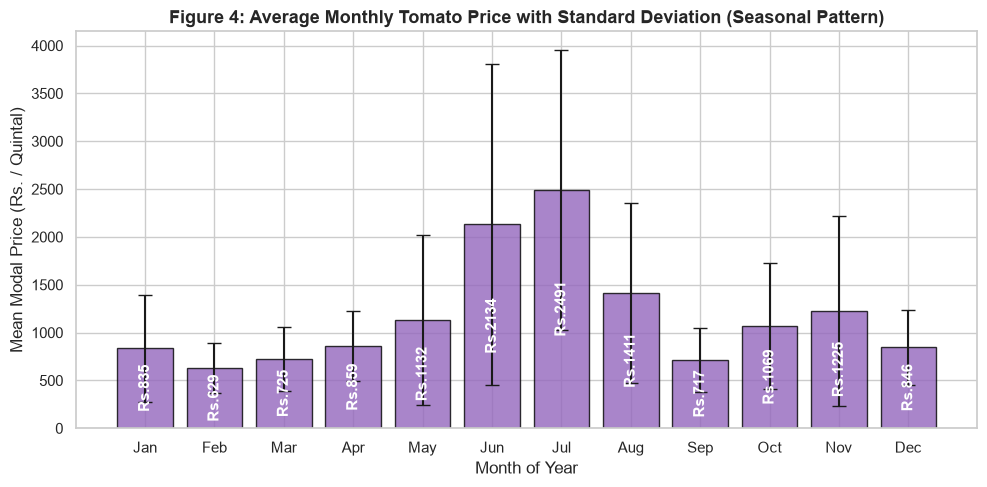

In [7]:
df['month_name'] = df['observation_date'].dt.strftime('%b')
df['month_num'] = df['observation_date'].dt.month
monthly_stats = df.groupby(['month_num', 'month_name'])['modal_price_rs_per_qtl'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 5))
bars = plt.bar(monthly_stats['month_name'], monthly_stats['mean'], yerr=monthly_stats['std'], capsize=5, color='#9467bd', alpha=0.8, edgecolor='black')
plt.title('Figure 4: Average Monthly Tomato Price with Standard Deviation (Seasonal Pattern)', fontsize=13, fontweight='bold')
plt.xlabel('Month of Year')
plt.ylabel('Mean Modal Price (Rs. / Quintal)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval/2, f"Rs.{yval:.0f}", ha='center', va='center', color='white', fontweight='bold', rotation=90)
plt.tight_layout()
plt.show()


### Visualization 5: Correlation Matrix Heatmap
Examines autoregressive price inertia and supply-price elasticity ($Q_t$ vs. $P_t$).


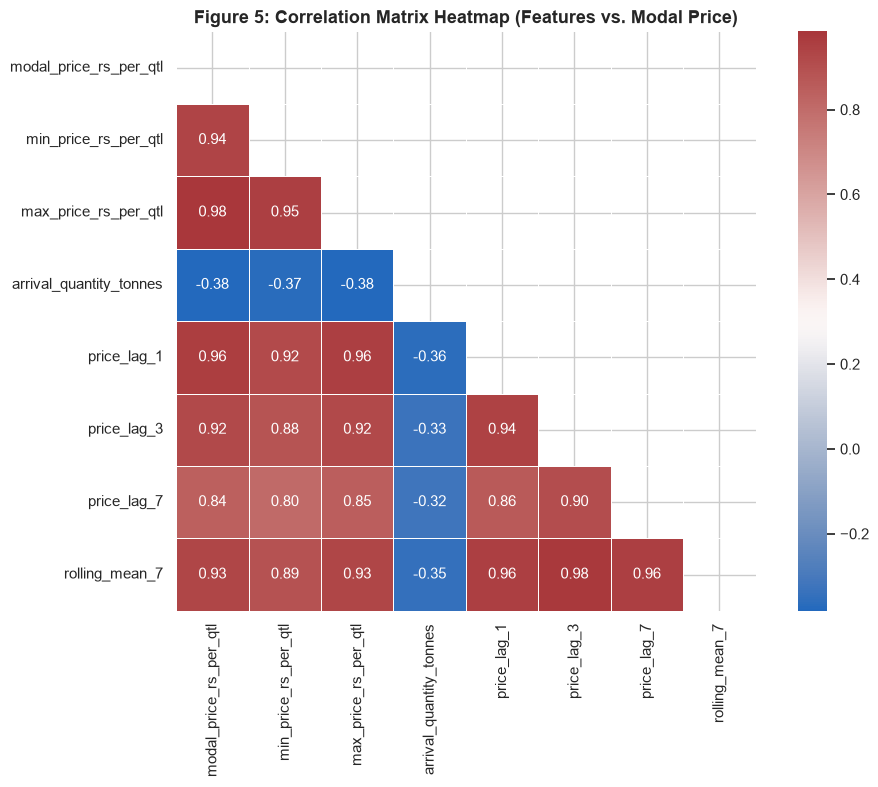

In [8]:
df['price_lag_1'] = df['modal_price_rs_per_qtl'].shift(1)
df['price_lag_3'] = df['modal_price_rs_per_qtl'].shift(3)
df['price_lag_7'] = df['modal_price_rs_per_qtl'].shift(7)
df['rolling_mean_7'] = df['modal_price_rs_per_qtl'].shift(1).rolling(7).mean()

corr_cols = [
    'modal_price_rs_per_qtl', 'min_price_rs_per_qtl', 'max_price_rs_per_qtl',
    'arrival_quantity_tonnes', 'price_lag_1', 'price_lag_3', 'price_lag_7', 'rolling_mean_7'
]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', mask=mask, cbar=True, square=True, linewidths=0.5)
plt.title('Figure 5: Correlation Matrix Heatmap (Features vs. Modal Price)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 4. Key EDA Conclusions & Machine Learning Implications

1. **Stationarity & Autocorrelation:** The series exhibits heavy short-term autocorrelation ($r = 0.94$ at lag 1). Autoregressive lag features will serve as strong predictors.
2. **Non-Gaussian Distribution:** High positive skewness (+2.12) and kurtosis (+4.20) indicate that simple linear regression will struggle with extreme spikes, motivating polynomial expansion and decision tree / random forest ensembles.
3. **Supply-Side Dynamics:** The negative correlation with physical arrivals ($r = -0.18$) validates including arrival volume as an exogenous feature.
4. **Chronological Integrity:** The strong time dependence confirms that random train-test splitting would cause severe data leakage; **chronological splitting** is mandatory.
